Over 89 days of production, 1,567 units were produced with a first-pass yield of 93.36%. 104 units failed end-of-line testing. The objective is to identify which of 590 monitored process parameters are associated with failure, and to recommend containment and corrective actions.

In [24]:
import pandas as pd
import numpy as np

# Features: 1567 production runs × 590 sensors, space-separated, no header
X = pd.read_csv('../data/secom.data', sep=' ', header=None)

# Labels: -1 = pass, 1 = fail, plus a timestamp
y = pd.read_csv('../data/secom_labels.data', sep=' ', header=None,
                names=['label', 'timestamp'])
y['timestamp'] = pd.to_datetime(y['timestamp'], format='%d/%m/%Y %H:%M:%S')

print('Features:', X.shape)
print('Labels:', y.shape)

# --- Baseline yield ---
n_total = len(y)
n_fail  = (y['label'] == 1).sum()
n_pass  = (y['label'] == -1).sum()
yield_pct = 100 * n_pass / n_total

print(f'\nTotal runs: {n_total}')
print(f'Pass: {n_pass}   Fail: {n_fail}')
print(f'Baseline yield: {yield_pct:.2f}%')
print(f'Defect rate: {100 - yield_pct:.2f}%')

# --- Time span ---
print(f'\nFrom {y.timestamp.min()} to {y.timestamp.max()}')
print(f'Span: {(y.timestamp.max() - y.timestamp.min()).days} days')

# --- Data quality ---
missing = X.isna().mean()
nunique = X.nunique(dropna=True)

print(f'\nColumns with any missing values: {(missing > 0).sum()}')
print(f'Columns >50% missing: {(missing > 0.5).sum()}')
print(f'Overall missing: {100 * missing.mean():.2f}%')
print(f'Constant columns (1 or 0 unique values): {(nunique <= 1).sum()}')

Features: (1567, 590)
Labels: (1567, 2)

Total runs: 1567
Pass: 1463   Fail: 104
Baseline yield: 93.36%
Defect rate: 6.64%

From 2008-07-19 11:55:00 to 2008-10-17 06:07:00
Span: 89 days

Columns with any missing values: 538
Columns >50% missing: 28
Overall missing: 4.54%
Constant columns (1 or 0 unique values): 116


In [25]:
from scipy.stats import chi2_contingency

y['fail'] = (y['label'] == 1).astype(int)
y['week'] = y['timestamp'].dt.isocalendar().week
y['dow']  = y['timestamp'].dt.day_name()

# Assume three 8-hour shifts
h = y['timestamp'].dt.hour
y['shift'] = np.select(
    [(h >= 6) & (h < 14), (h >= 14) & (h < 22)],
    ['A (06-14)', 'B (14-22)'],
    'C (22-06)'
)

def stratify(col):
    g = y.groupby(col).agg(n=('fail', 'size'), fails=('fail', 'sum'))
    g['fail_rate_%'] = (100 * g['fails'] / g['n']).round(2)
    ct = pd.crosstab(y[col], y['fail'])
    chi2, p, dof, _ = chi2_contingency(ct)
    print(f'\n--- by {col} ---')
    print(g.to_string())
    print(f'chi-square p-value: {p:.4f}')
    return g

wk    = stratify('week')
shift = stratify('shift')
dow   = stratify('dow')


--- by week ---
        n  fails  fail_rate_%
week                         
29     13      3        23.08
30     21      2         9.52
31     48     10        20.83
32    108     14        12.96
33     51      7        13.73
34    208     22        10.58
35    169      7         4.14
36    133      2         1.50
37     95      4         4.21
38    154      5         3.25
39    166      4         2.41
40    169     15         8.88
41    138      8         5.80
42     94      1         1.06
chi-square p-value: 0.0000

--- by shift ---
             n  fails  fail_rate_%
shift                             
A (06-14)  492     31         6.30
B (14-22)  568     40         7.04
C (22-06)  507     33         6.51
chi-square p-value: 0.8809

--- by dow ---
             n  fails  fail_rate_%
dow                               
Friday     242     13         5.37
Monday     243     17         7.00
Saturday   204     13         6.37
Sunday     199     21        10.55
Thursday   236     15         

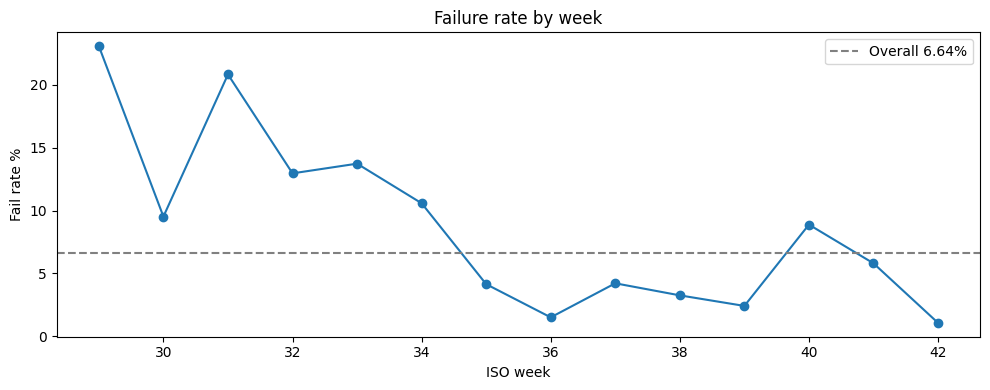

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wk.index, wk['fail_rate_%'], marker='o')
ax.axhline(6.64, color='gray', linestyle='--', label='Overall 6.64%')
ax.set_xlabel('ISO week')
ax.set_ylabel('Fail rate %')
ax.set_title('Failure rate by week')
ax.legend()
plt.tight_layout()
plt.show()

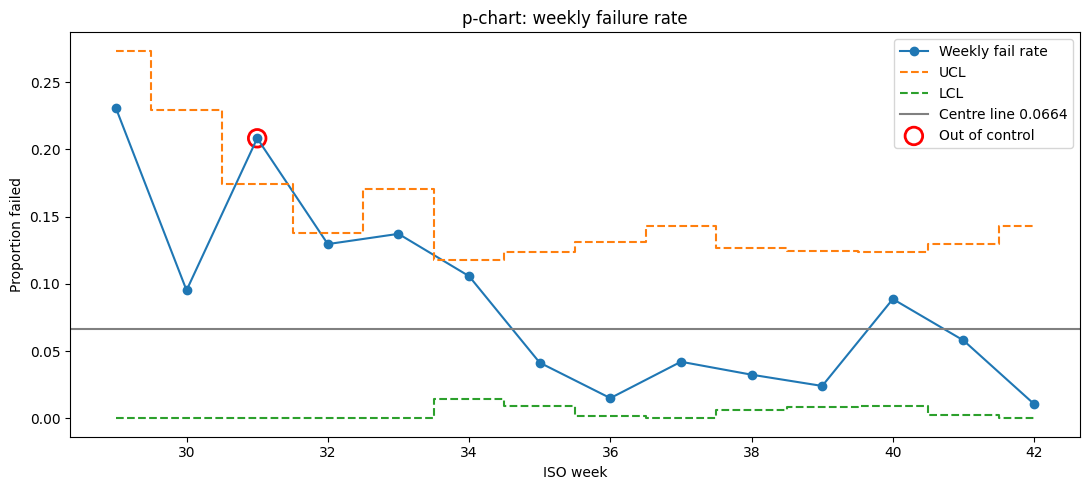

        n  fails       p     LCL     UCL  out_of_control
week                                                    
29     13      3  0.2308  0.0000  0.2735           False
30     21      2  0.0952  0.0000  0.2293           False
31     48     10  0.2083  0.0000  0.1742            True
32    108     14  0.1296  0.0000  0.1382           False
33     51      7  0.1373  0.0000  0.1709           False
34    208     22  0.1058  0.0146  0.1181           False
35    169      7  0.0414  0.0089  0.1238           False
36    133      2  0.0150  0.0016  0.1311           False
37     95      4  0.0421  0.0000  0.1430           False
38    154      5  0.0325  0.0062  0.1265           False
39    166      4  0.0241  0.0084  0.1243           False
40    169     15  0.0888  0.0089  0.1238           False
41    138      8  0.0580  0.0028  0.1299           False
42     94      1  0.0106  0.0000  0.1434           False


In [27]:
# p-chart: proportion defective, weekly
w = y.groupby('week').agg(n=('fail','size'), fails=('fail','sum'))
p_bar = y['fail'].mean()                      # overall centre line

w['p']   = w['fails'] / w['n']
w['UCL'] = p_bar + 3*np.sqrt(p_bar*(1-p_bar)/w['n'])
w['LCL'] = (p_bar - 3*np.sqrt(p_bar*(1-p_bar)/w['n'])).clip(lower=0)
w['out_of_control'] = (w['p'] > w['UCL']) | (w['p'] < w['LCL'])

fig, ax = plt.subplots(figsize=(11,5))
ax.plot(w.index, w['p'], marker='o', label='Weekly fail rate')
ax.step(w.index, w['UCL'], where='mid', linestyle='--', label='UCL')
ax.step(w.index, w['LCL'], where='mid', linestyle='--', label='LCL')
ax.axhline(p_bar, color='gray', label=f'Centre line {p_bar:.4f}')

ooc = w[w['out_of_control']]
ax.scatter(ooc.index, ooc['p'], s=160, facecolors='none', edgecolors='red',
           linewidths=2, label='Out of control')

ax.set_xlabel('ISO week'); ax.set_ylabel('Proportion failed')
ax.set_title('p-chart: weekly failure rate')
ax.legend(); plt.tight_layout(); plt.show()

print(w[['n','fails','p','LCL','UCL','out_of_control']].round(4).to_string())

In [28]:
y['phase'] = np.where(y['week'] < 35, 'P1 (wk29-34)', 'P2 (wk35-42)')

for phase, sub in y.groupby('phase'):
    p_bar = sub['fail'].mean()
    w = sub.groupby('week').agg(n=('fail','size'), fails=('fail','sum'))
    w['p']   = w['fails']/w['n']
    w['UCL'] = p_bar + 3*np.sqrt(p_bar*(1-p_bar)/w['n'])
    w['LCL'] = (p_bar - 3*np.sqrt(p_bar*(1-p_bar)/w['n'])).clip(lower=0)
    w['signal'] = np.where(w['p'] > w['UCL'], 'ABOVE UCL', '')
    print(f'\n{phase}: centre line {100*p_bar:.2f}%  (n={len(sub)}, fails={sub["fail"].sum()})')
    print(w.round(4).to_string())


P1 (wk29-34): centre line 12.92%  (n=449, fails=58)
        n  fails       p     UCL     LCL signal
week                                           
29     13      3  0.2308  0.4082  0.0000       
30     21      2  0.0952  0.3487  0.0000       
31     48     10  0.2083  0.2744  0.0000       
32    108     14  0.1296  0.2260  0.0324       
33     51      7  0.1373  0.2701  0.0000       
34    208     22  0.1058  0.1989  0.0594       

P2 (wk35-42): centre line 4.11%  (n=1118, fails=46)
        n  fails       p     UCL  LCL     signal
week                                            
35    169      7  0.0414  0.0870  0.0           
36    133      2  0.0150  0.0928  0.0           
37     95      4  0.0421  0.1023  0.0           
38    154      5  0.0325  0.0892  0.0           
39    166      4  0.0241  0.0874  0.0           
40    169     15  0.0888  0.0870  0.0  ABOVE UCL
41    138      8  0.0580  0.0919  0.0           
42     94      1  0.0106  0.1026  0.0           


In [29]:
nunique = X.nunique(dropna=True)
missing = X.isna().mean()

constant_cols = set(nunique[nunique <= 1].index)      # 116
sparse_cols   = set(missing[missing > 0.5].index)     # 28
drop_cols     = constant_cols | sparse_cols

keep = [c for c in X.columns if c not in drop_cols]
X_clean = X[keep].copy()

print(f'Dropped {len(constant_cols)} constant, {len(sparse_cols)} >50% missing')
print(f'Overlap between the two groups: {len(constant_cols & sparse_cols)}')
print(f'Sensors retained: {X_clean.shape[1]}')
print(f'Remaining missing: {100*X_clean.isna().mean().mean():.2f}%')
print(f'Rows with at least one missing value: {(X_clean.isna().sum(axis=1) > 0).sum()}')

X_imp = X_clean.fillna(X_clean.median())
print(f'NaNs after imputation: {X_imp.isna().sum().sum()}')
print(f'Final shape: {X_imp.shape}')

# Carry the labels alongside
X_imp = X_imp.reset_index(drop=True)
labels = y[['label','fail','timestamp','week','shift','phase']].reset_index(drop=True)

Dropped 116 constant, 28 >50% missing
Overlap between the two groups: 0
Sensors retained: 446
Remaining missing: 1.56%
Rows with at least one missing value: 1106
NaNs after imputation: 0
Final shape: (1567, 446)


In [31]:
from scipy import stats

def fdr_bh(pvals):
    p = np.asarray(pvals, dtype=float)
    n = len(p)
    order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.clip(np.minimum.accumulate(adj[::-1])[::-1], 0, 1)
    out = np.empty(n)
    out[order] = adj
    return out

def compare_groups(X_data, fail_flags):
    f = X_data[fail_flags == 1]
    p = X_data[fail_flags == 0]
    rows = []
    for c in X_data.columns:
        a, b = f[c].values, p[c].values
        t_stat, p_t = stats.ttest_ind(a, b, equal_var=False)
        _,      p_mw = stats.mannwhitneyu(a, b, alternative='two-sided')
        pooled_sd = np.sqrt(((len(a)-1)*a.std(ddof=1)**2 + (len(b)-1)*b.std(ddof=1)**2)
                            / (len(a)+len(b)-2))
        d = (a.mean() - b.mean()) / pooled_sd if pooled_sd > 0 else 0
        rows.append((c, p_t, p_mw, d))

    r = pd.DataFrame(rows, columns=['sensor','p_t','p_mw','cohen_d'])
    r['p_adj']    = fdr_bh(r['p_t'])
    r['p_adj_mw'] = fdr_bh(r['p_mw'])
    return r.sort_values('p_adj')

results_all = compare_groups(X_imp, labels['fail'].values)

print(f"Raw p < 0.05:             {(results_all['p_t'] < 0.05).sum()}")
print(f"After FDR (t-test):       {(results_all['p_adj'] < 0.05).sum()}")
print(f"After FDR (Mann-Whitney): {(results_all['p_adj_mw'] < 0.05).sum()}")
print(results_all.head(10).round(5).to_string(index=False))

Raw p < 0.05:             80
After FDR (t-test):       22
After FDR (Mann-Whitney): 25
 sensor     p_t    p_mw  cohen_d   p_adj  p_adj_mw
    129 0.00000 0.00005  0.41490 0.00003   0.00260
     59 0.00000 0.00000  0.63409 0.00006   0.00000
    103 0.00000 0.00000  0.61421 0.00009   0.00000
     28 0.00002 0.00007 -0.43200 0.00202   0.00369
    316 0.00008 0.00019 -0.36030 0.00667   0.00653
    125 0.00009 0.00148 -0.33699 0.00667   0.03558
    130 0.00014 0.00837  0.30840 0.00903   0.08677
    428 0.00028 0.00672 -0.10630 0.01035   0.08126
    122 0.00020 0.00280 -0.31542 0.01035   0.04998
    112 0.00022 0.00279  0.11470 0.01035   0.04998


In [32]:
mask = labels['phase'].astype(str).str.startswith('P2').values

results_p2 = compare_groups(X_imp[mask].reset_index(drop=True),
                            labels['fail'][mask].values)

print('=== PHASE 2 ONLY (weeks 35-42, stable period) ===')
print(f"Units: {mask.sum()}, failures: {labels['fail'][mask].sum()}")
print(f"Raw p < 0.05:             {(results_p2['p_t'] < 0.05).sum()}")
print(f"After FDR (t-test):       {(results_p2['p_adj'] < 0.05).sum()}")
print(f"After FDR (Mann-Whitney): {(results_p2['p_adj_mw'] < 0.05).sum()}")
print(results_p2.head(10).round(5).to_string(index=False))

sig_all = set(results_all.loc[results_all['p_adj'] < 0.05, 'sensor'])
sig_p2  = set(results_p2.loc[results_p2['p_adj']  < 0.05, 'sensor'])
print(f'\nAll data: {len(sig_all)} | Phase 2: {len(sig_p2)} | In both: {len(sig_all & sig_p2)}')
print('In both:', sorted(sig_all & sig_p2))
print('Only on all data:', sorted(sig_all - sig_p2))

=== PHASE 2 ONLY (weeks 35-42, stable period) ===
Units: 1118, failures: 46
Raw p < 0.05:             58
After FDR (t-test):       17
After FDR (Mann-Whitney): 0
 sensor     p_t    p_mw  cohen_d   p_adj  p_adj_mw
    155 0.00002 0.69433 -0.14846 0.00528   0.92212
    428 0.00002 0.66214 -0.14285 0.00528   0.92212
    151 0.00016 0.03427 -0.13482 0.01737   0.31189
    424 0.00013 0.03391 -0.14448 0.01737   0.31189
    521 0.00042 0.45346 -0.11025 0.03228   0.82212
    290 0.00045 0.65909 -0.12188 0.03228   0.92212
    286 0.00055 0.08441 -0.12144 0.03228   0.50871
     55 0.00058 0.00167 -0.48882 0.03228   0.09968
    575 0.00077 0.16138 -0.27465 0.03807   0.56728
     31 0.00094 0.53634 -0.35243 0.03816   0.86984

All data: 22 | Phase 2: 17 | In both: 7
In both: [56, 121, 129, 155, 428, 573, 575]
Only on all data: [19, 28, 59, 103, 112, 122, 124, 125, 127, 130, 180, 316, 452, 510, 577]


In [33]:
for s in [59, 103, 129, 28, 316]:
    p1 = X_imp.loc[labels['phase'].str.startswith('P1').values, s]
    p2 = X_imp.loc[labels['phase'].str.startswith('P2').values, s]
    t, p = stats.ttest_ind(p1, p2, equal_var=False)
    print(f'sensor {s}: P1 mean={p1.mean():.3f}  P2 mean={p2.mean():.3f}  p={p:.2e}')

# And within Phase 1 only, do they relate to failure?
m1 = labels['phase'].str.startswith('P1').values
for s in [59, 103, 129]:
    f = X_imp.loc[m1 & (labels['fail']==1).values, s]
    q = X_imp.loc[m1 & (labels['fail']==0).values, s]
    print(f'sensor {s} within P1: p={stats.ttest_ind(f, q, equal_var=False)[1]:.4f}')

sensor 59: P1 mean=9.496  P2 mean=0.323  p=7.74e-43
sensor 103: P1 mean=-0.007  P2 mean=-0.011  p=1.96e-93
sensor 129: P1 mean=0.058  P2 mean=-0.797  p=6.09e-69
sensor 28: P1 mean=66.600  P2 mean=70.663  p=6.38e-112
sensor 316: P1 mean=5.607  P2 mean=6.126  p=1.62e-19
sensor 59 within P1: p=0.0117
sensor 103 within P1: p=0.2588
sensor 129 within P1: p=0.8893


In [34]:
m1 = labels['phase'].astype(str).str.startswith('P1').values
m2 = ~m1

rows = []
for c in X_imp.columns:
    a, b = X_imp.loc[m1, c].values, X_imp.loc[m2, c].values
    _, p_t  = stats.ttest_ind(a, b, equal_var=False)
    _, p_mw = stats.mannwhitneyu(a, b, alternative='two-sided')
    pooled_sd = np.sqrt(((len(a)-1)*a.std(ddof=1)**2 + (len(b)-1)*b.std(ddof=1)**2)
                        / (len(a)+len(b)-2))
    d = (b.mean() - a.mean()) / pooled_sd if pooled_sd > 0 else 0   # P2 minus P1
    rows.append((c, p_t, p_mw, d))

shift = pd.DataFrame(rows, columns=['sensor','p_t','p_mw','d'])
shift['p_adj']    = fdr_bh(shift['p_t'])
shift['p_adj_mw'] = fdr_bh(shift['p_mw'])
shift['abs_d']    = shift['d'].abs()

robust = shift[(shift['p_adj'] < 0.05) & (shift['p_adj_mw'] < 0.05)]

print(f'Sensors that shifted (FDR, t-test):   {(shift["p_adj"] < 0.05).sum()}')
print(f'Shifted under BOTH tests:             {len(robust)}')
print(f'With large effect (|d| > 0.8):        {(robust["abs_d"] > 0.8).sum()}')
print(robust.sort_values('abs_d', ascending=False).head(10)
          [['sensor','d','p_adj','p_adj_mw']].round(5).to_string(index=False))

Sensors that shifted (FDR, t-test):   241
Shifted under BOTH tests:             212
With large effect (|d| > 0.8):        7
 sensor        d  p_adj  p_adj_mw
     28  1.38595    0.0       0.0
    103 -1.34002    0.0       0.0
     79 -1.29648    0.0       0.0
     78  1.12938    0.0       0.0
     59 -1.07143    0.0       0.0
    542  0.86972    0.0       0.0
    510 -0.82740    0.0       0.0
    169  0.79043    0.0       0.0
    440  0.78199    0.0       0.0
    304  0.77305    0.0       0.0


In [35]:
top = robust.sort_values('abs_d', ascending=False)['sensor'].head(5).tolist()
wk = labels['week'].values

for s in top:
    w40  = X_imp.loc[(wk == 40), s]
    rest = X_imp.loc[m2 & (wk != 40), s]
    _, p = stats.ttest_ind(w40, rest, equal_var=False)
    z = (w40.mean() - rest.mean()) / rest.std()
    print(f'sensor {s}: wk40 mean={w40.mean():.4f}  P2-rest={rest.mean():.4f}  z={z:+.2f}  p={p:.4f}')

sensor 28: wk40 mean=70.8321  P2-rest=70.6332  z=+0.06  p=0.3899
sensor 103: wk40 mean=-0.0103  P2-rest=-0.0109  z=+0.22  p=0.0079
sensor 79: wk40 mean=-0.0148  P2-rest=-0.0020  z=-0.84  p=0.0000
sensor 78: wk40 mean=0.0201  P2-rest=-0.0035  z=+0.51  p=0.0000
sensor 59: wk40 mean=-0.2855  P2-rest=0.4310  z=-0.10  p=0.0401


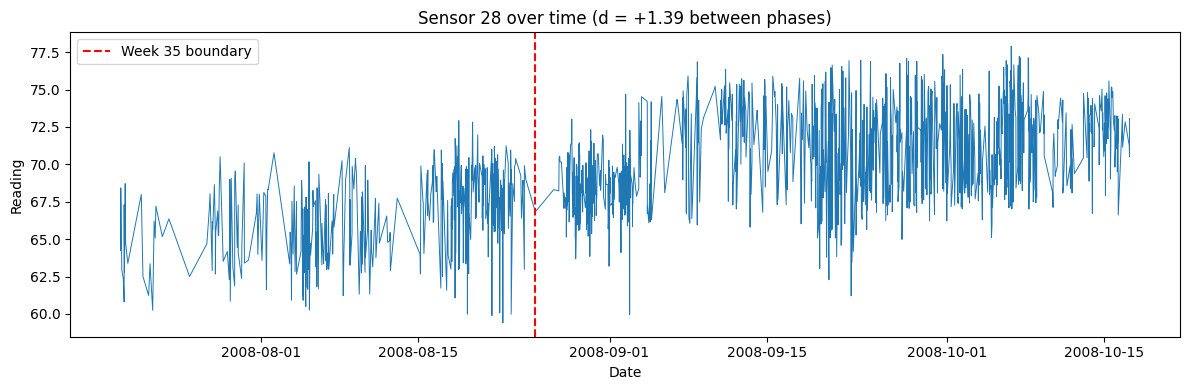

In [36]:
s = 28
vals = X_imp[s].values
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(labels['timestamp'], vals, lw=0.7)
ax.axvline(labels.loc[m2, 'timestamp'].min(), color='red', ls='--', label='Week 35 boundary')
ax.set_title(f'Sensor {s} over time (d = +1.39 between phases)')
ax.set_xlabel('Date'); ax.set_ylabel('Reading'); ax.legend()
plt.tight_layout(); plt.show()

## Step 7: FMEA and recommendations

### Risk assessment (S × O × D = RPN)

| # | Failure mode | Effect | Potential cause | Current control | S | O | D | RPN |
|---|---|---|---|---|---|---|---|---|
| 1 | Process drifts back to Phase 1 operating conditions | Failure rate returns to ~13%, 3x scrap | Week-35 change is undocumented and uncontrolled | None - no SPC on the shifted parameters | 8 | 5 | 9 | 360 |
| 2 | 116 sensors report a constant value | Parameter could drift with no alarm | Stuck or failed sensor / dead channel | None - undetected for 89 days | 7 | 6 | 10 | 420 |
| 3 | Week-40 type excursion recurs undetected | ~2x failure rate for a week | Unknown; sensors 78 and 79 shifted during it | Weekly yield review, after the fact | 7 | 5 | 8 | 280 |
| 4 | End-of-line test changes without notice | Yield numbers not comparable; false improvement | No change control linking test revisions to yield | None identified | 6 | 3 | 9 | 162 |

### Recommendations

**Containment (days)**
- p-chart monitoring on weekly yield, limits set from the Phase 2 period, so an excursion like week 40 is flagged within a week.
- Audit the 116 constant-value sensors with maintenance; restore or formally retire each.

**Corrective (weeks)**
- Identify and document what changed around week 35 (ramp, recipe, equipment or test) and write it into the control plan.
- Investigate week 40, starting from sensors 78 and 79, which both shifted significantly that week.
- I-MR charts on the highest-impact shifted parameters (28, 103, 79, 78, 59) to catch drift back toward Phase 1 conditions.

**Preventive (ongoing)**
- Change control: log any revision to the end-of-line test alongside yield data, so a measurement change cannot be mistaken for a process improvement.
- Re-run capability analysis once the process is confirmed stable and spec limits are available.

### Limitations

No individual sensor showed a robust association with failure within the stable period. Apparent associations across the full dataset were confounded with the week-35 process change: the strongest candidates (59, 103, 129) differ enormously between phases but show no relationship to failure within Phase 1 alone (p = 0.26 and p = 0.89). In Phase 2, 17 sensors clear the t-test but none survive Mann-Whitney, indicating those differences are driven by outliers rather than a genuine distribution shift.

Spec limits were not available in this dataset, so Cp and Cpk could not be calculated.

The phase boundary at week 35 was derived from yield data, not from a documented event. Sensor 28 shows a gradual rather than stepped transition, and weekly volume rose from 13 to roughly 200 units over the same period, which is consistent with a production ramp. Confirmation requires production records.